In [1]:
pip install tensorflow numpy matplotlib seaborn scikit-learn pillow

In [2]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Import necessary libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing import image

print(f"TensorFlow Version: {tf.__version__}")

Mounted at /content/drive
TensorFlow Version: 2.20.0


In [3]:
# Define dataset paths based on your Google Drive structure
base_dir = '/content/drive/My Drive/Archive'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Standardize image size and batch size
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32

# Data Generators: Rescale pixel values from 0-255 to 0-1
# Add augmentation ONLY to the training data
train_datagen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=10
)

# Validation and Test sets should only be scaled, NOT augmented
val_test_datagen = ImageDataGenerator(rescale=1./255)

print("Loading Training Data:")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary' # Binary classification: Normal vs Pneumonia
)

print("\Loading Validation Data:")
val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

print("\Loading Testing Data:")
test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=1, # Set to 1 for accurate evaluation and confusion matrix
    class_mode='binary',
    shuffle=False # Do not shuffle test data to match labels with predictions
)

Loading Training Data:


<>:32: SyntaxWarning: invalid escape sequence '\L'
<>:40: SyntaxWarning: invalid escape sequence '\L'
<>:32: SyntaxWarning: invalid escape sequence '\L'
<>:40: SyntaxWarning: invalid escape sequence '\L'
/tmp/ipykernel_1314/3519672286.py:32: SyntaxWarning: invalid escape sequence '\L'
  print("\Loading Validation Data:")
/tmp/ipykernel_1314/3519672286.py:40: SyntaxWarning: invalid escape sequence '\L'
  print("\Loading Testing Data:")


Found 700 images belonging to 2 classes.
\Loading Validation Data:
Found 16 images belonging to 2 classes.
\Loading Testing Data:
Found 300 images belonging to 2 classes.


In [4]:
model = Sequential([
    # 1st Convolutional Block
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    MaxPooling2D(2, 2),

    # 2nd Convolutional Block
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # 3rd Convolutional Block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # 4th Convolutional Block
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Flattening and Dense Layers
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5), # Dropout helps prevent the model from memorizing the training set
    Dense(1, activation='sigmoid') # Sigmoid for binary classification (0 or 1)
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Callbacks to optimize training
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_pneumonia_model.h5', monitor='val_accuracy', save_best_only=True)

EPOCHS = 5

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5109 - loss: 0.6930

22/22 ━━━━━━━━━━━━━━━━━━━━ 129s 6s/step - accuracy: 0.5271 - loss: 0.6872 - val_accuracy: 0.5000 - val_loss: 0.6673
Epoch 2/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.6873 - loss: 0.6179

22/22 ━━━━━━━━━━━━━━━━━━━━ 14s 618ms/step - accuracy: 0.7229 - loss: 0.5943 - val_accuracy: 0.6875 - val_loss: 0.6330
Epoch 3/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.7410 - loss: 0.5149

22/22 ━━━━━━━━━━━━━━━━━━━━ 14s 617ms/step - accuracy: 0.7614 - loss: 0.5118 - val_accuracy: 0.8750 - val_loss: 0.3084
Epoch 4/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 608ms/step - accuracy: 0.8657 - loss: 0.3528 - val_accuracy: 0.7500 - val_loss: 0.4919
Epoch 5/5
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 588ms/step - accuracy: 0.8514 - loss: 0.3805 - val_accuracy: 0.8750 - val_loss: 0.3441


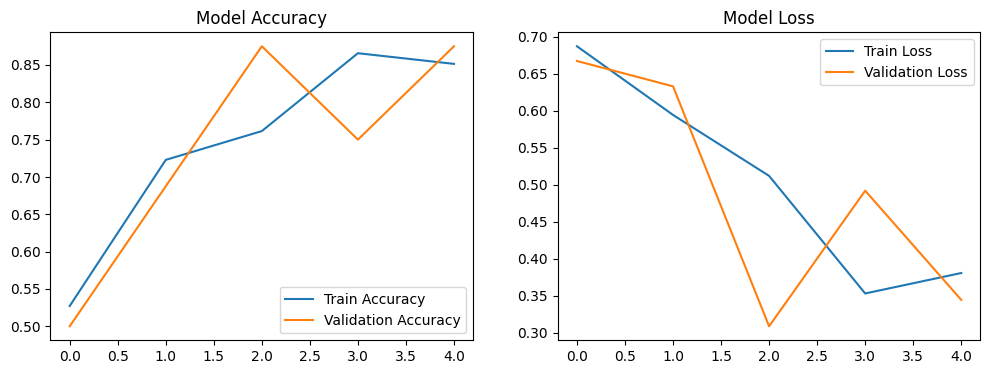

300/300 ━━━━━━━━━━━━━━━━━━━━ 93s 308ms/step - accuracy: 0.7600 - loss: 0.5344

Test Accuracy: 76.00%
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step


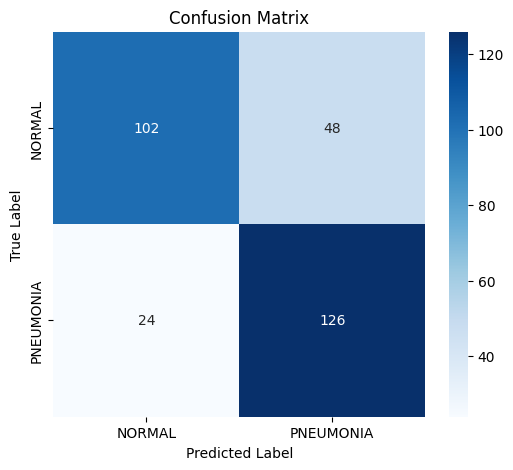


Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.81      0.68      0.74       150
   PNEUMONIA       0.72      0.84      0.78       150

    accuracy                           0.76       300
   macro avg       0.77      0.76      0.76       300
weighted avg       0.77      0.76      0.76       300



In [6]:
# Plot Training History
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

# Evaluate on Test Set
test_loss, test_acc = model.evaluate(test_generator)
print(f"\nTest Accuracy: {test_acc*100:.2f}%")

# Confusion Matrix & Classification Report
predictions = model.predict(test_generator)
predictions = np.where(predictions > 0.5, 1, 0) # Convert probabilities to 0 or 1

true_labels = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

cm = confusion_matrix(true_labels, predictions)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(true_labels, predictions, target_names=class_labels))

In [7]:
def predict_xray(image_path, trained_model):
    """
    Loads an image, processes it to match the model's expected format,
    and prints the prediction.
    """
    img = image.load_img(image_path, target_size=(IMG_HEIGHT, IMG_WIDTH))

    # Display the image
    plt.imshow(img)
    plt.axis('off')
    plt.show()

    # Convert image to array and expand dimensions
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array /= 255.0 # Scale just like the training data

    # Predict
    prediction = trained_model.predict(img_array)[0][0]

    # The generator maps 'Normal' to 0 and 'Pneumonia' to 1 usually,
    # but let's check class_indices dynamically
    class_mapping = {v: k for k, v in train_generator.class_indices.items()}

    predicted_class_num = 1 if prediction > 0.5 else 0
    predicted_class_name = class_mapping[predicted_class_num]
    confidence = prediction if predicted_class_num == 1 else 1 - prediction

    print(f"Prediction: {predicted_class_name.upper()}")
    print(f"Confidence: {confidence*100:.2f}%")
